In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import io
import re
import html
import joblib

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay


In [ ]:
df=pd.read_csv("/content/IMDB Dataset.csv")

In [ ]:
df

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
...,...,...
49995,I thought this movie did a down right good job...,positive
49996,"Bad plot, bad dialogue, bad acting, idiotic di...",negative
49997,I am a Catholic taught in parochial elementary...,negative
49998,I'm going to have to disagree with the previou...,negative


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB


The dataset is complete and contains 50,000 reviews with their sentiment labels.

In [ ]:
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [ ]:
df.describe()

,review,sentiment
count,50000,50000
unique,49582,2
top,Loved today's show!!! It was a variety and not...,positive
freq,5,25000


In [ ]:
df.columns

Index(['review', 'sentiment'], dtype='object')

In [ ]:
df.columns.tolist()

['review', 'sentiment']

In [ ]:
df.isnull().sum()

,0
review,0
sentiment,0


In [ ]:
df.duplicated().sum()

np.int64(418)

In [ ]:
df = df.drop_duplicates().reset_index(drop=True)
df

,review,sentiment,review_length
0,One of the other reviewers has mentioned that ...,positive,307
1,A wonderful little production. <br /><br />The...,positive,162
2,I thought this was a wonderful way to spend ti...,positive,166
3,Basically there's a family where a little boy ...,negative,138
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,230
...,...,...,...
49577,I thought this movie did a down right good job...,positive,194
49578,"Bad plot, bad dialogue, bad acting, idiotic di...",negative,112
49579,I am a Catholic taught in parochial elementary...,negative,230
49580,I'm going to have to disagree with the previou...,negative,212


In [ ]:
df["sentiment"].value_counts()

,count
sentiment,
positive,25000
negative,25000


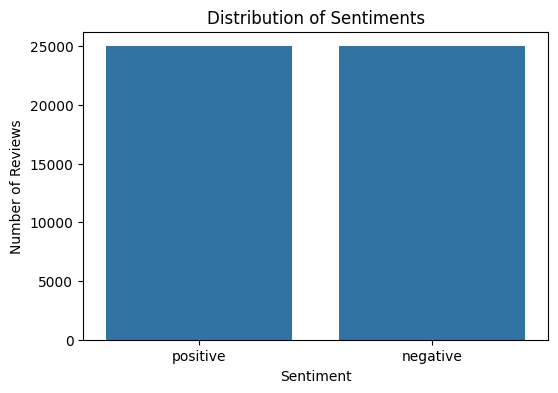

In [ ]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="sentiment")
plt.title("Distribution of Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

The dataset is balanced with 25,000 positive and 25,000 negative reviews.


In [ ]:
df["review_length"] = df["review"].fillna("").apply(lambda x: len(x.split()))


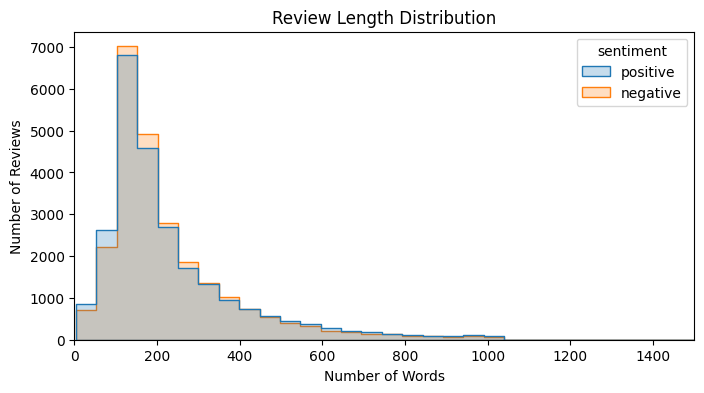

In [ ]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df,x="review_length",hue="sentiment",bins=50,element="step")
plt.title("Review Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.xlim(0, 1500)
plt.show()

Most people write short reviews and only a few write very long reviews.

In [ ]:
X = df["review"]
y = df["sentiment"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 35000
Validation: 7500
Testing: 7500


In [ ]:
tfidf = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("Training shape:", X_train_tfidf.shape)
print("Validation shape:", X_val_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

Training shape: (35000, 30000)
Validation shape: (7500, 30000)
Testing shape: (7500, 30000)


In [ ]:
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression( max_iter=1000,random_state=42),
    "Linear SVC": LinearSVC(random_state=42)
}
results = []
trained_models = {}


for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_val_tfidf)


    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred, pos_label="positive"
        ),
        "Recall": recall_score(y_val, y_pred, pos_label="positive"),

        "F1 Score": f1_score(
            y_val, y_pred, pos_label="positive"
        )
    })

    trained_models[name] = model


results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score
2,Linear SVC,0.906667,0.904295,0.909600,0.906940
1,Logistic Regression,0.900800,0.898040,0.904267,0.901143
0,Naive Bayes,0.871333,0.868289,0.875467,0.871863


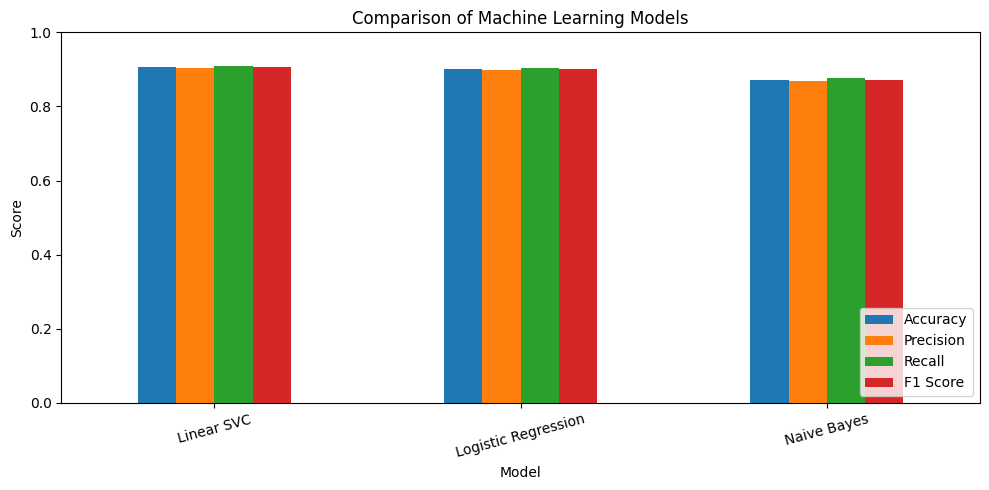

In [ ]:
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]].plot(kind="bar",figsize=(10, 5))
plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Linear SVC and Logistic Regression perfrom slightly better that Naive Bayes.

In [ ]:
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

best_name

'Linear SVC'

In [ ]:
y_test_pred = best_model.predict(X_test_tfidf)
print("Final Model:", best_name)

Final Model: Linear SVC


In [ ]:
print(classification_report(
    y_test,
    y_test_pred,
    labels=["negative", "positive"],
    digits=4
))

              precision    recall  f1-score   support

    negative     0.9155    0.9045    0.9100      3750
    positive     0.9057    0.9165    0.9111      3750

    accuracy                         0.9105      7500
   macro avg     0.9106    0.9105    0.9105      7500
weighted avg     0.9106    0.9105    0.9105      7500



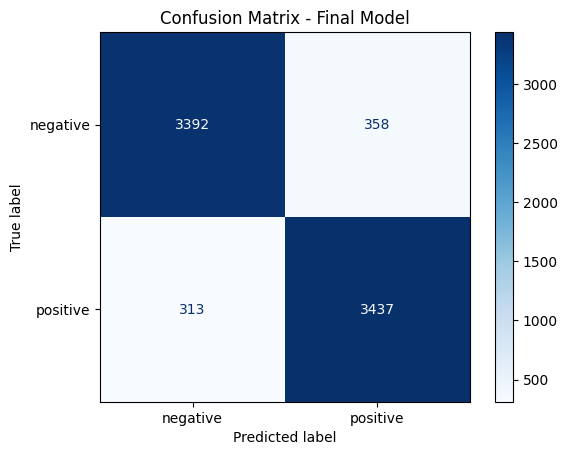

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    labels=["negative", "positive"],
    cmap="Blues"
)

plt.title("Confusion Matrix - Final Model")
plt.show()

In [ ]:
saved_model = {
    "vectorizer": tfidf,
    "model": best_model
}

In [ ]:
joblib.dump(saved_model,"sentiment_analysis_model.pkl")

print("Model and vectorizer saved successfully")

Model and vectorizer saved successfully


In [ ]:
loaded_model = joblib.load("sentiment_analysis_model.pkl")
X_sample = loaded_model["vectorizer"].transform(X_test.iloc[:5])
test_prediction = loaded_model["model"].predict(X_sample)

test_prediction

array(['negative', 'positive', 'negative', 'negative', 'positive'],
      dtype=object)

The model predicted 3 reviews as negative and 2 as positive.